# ATER-MOB I - Analyse exploratoire des données
---
**Mobilité et sécurité routière au Togo** · Notebook 01 : exploration des 8 datasets + limites administratives

**Objectif de ce notebook.** Comprendre la structure, la qualité et les pièges de chaque dataset *avant* tout traitement. Ce notebook **ne modifie aucune donnée** : il diagnostique. Les corrections feront l'objet du notebook suivant.

| Étape | Contenu |
|---|---|
| 0 | Configuration et fonctions utilitaires |
| 1 | `transports_terrestres` (parc, accidents, blessés, morts…) |
| 2 | `permis_conduire` |
| 3 | `immatriculations_2` |
| 4 | `immatriculations_1` (et rapprochement avec `immatriculations_2`) |
| 5 | `reseau_routier` (piège des lignes TOTAL) |
| 6 | `routes_classees` (géométries conservées telles quelles, sans simplification) |
| 7 | `entreprises_auto_ecoles` |
| 8 | `pop_rgph5_tg` |
| 9 | Limites administratives (GeoJSON régions et préfectures) |
| 10 | Contrôles croisés : jointures géographiques et cohérence des périodes |
| 11 | Bilan : liste des anomalies et fiche de synthèse à partager |

**Mode d'emploi.** Placez les fichiers dans le dossier `data_rep` (étape 0), adaptez les noms de fichiers si besoin, puis exécutez le notebook de haut en bas. Chaque section affiche des alertes pour les anomalies détectées ; elles sont toutes reprises dans le bilan final (étape 11).

## 0. Configuration et fonctions utilitaires

In [38]:
import re, ast, difflib, unicodedata, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely import wkt as shp_wkt
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})

# ------------------------------------------------------------------ CONFIGURATION (à adapter)
data_rep = Path("main/data")                      # dossier contenant les fichiers
FILES = {
    "transports":  "transports_terrestres.csv",
    "permis":      "permis_conduire.csv",
    "immat2":      "immatriculations_2.csv",
    "immat1":      "immatriculations_1.csv",
    "reseau":      "reseau_routier.csv",
    "routes":      "routes_classees.csv",
    "autoecoles":  "entreprises_auto_ecoles.csv",
    "pop":         "pop_rgph5_tg.csv",
}
GEOJSON_REGIONS     = data_rep / "regions.geojson"       # adapter le nom du fichier
GEOJSON_PREFECTURES = data_rep / "prefectures.geojson"   # adapter le nom du fichier

CRS_GEO  = "EPSG:4326"    # coordonnées géographiques (lon, lat)
CRS_PROJ = "EPSG:32631"   # UTM 31N : calcul des longueurs en mètres
TOGO_BBOX = (-0.2, 5.9, 1.9, 11.2)   # lon_min, lat_min, lon_max, lat_max (contrôle de plausibilité)

ISSUES = []      # anomalies détectées (reprises au bilan)
SUMMARY = {}     # fiche de synthèse (reprise au bilan)

def flag(msg):
    ISSUES.append(msg)
    print("⚠️ ", msg)

# ------------------------------------------------------------------ Lecture et normalisation
def read_csv_robust(path):
    # Lit un CSV en essayant plusieurs encodages et séparateurs.
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Fichier introuvable : {path.resolve()}")
    last = None
    for enc in ("utf-8-sig", "utf-8", "latin-1"):
        for sep in (",", ";", "\t"):
            try:
                df = pd.read_csv(path, sep=sep, encoding=enc, low_memory=False)
                if df.shape[1] > 1:
                    print(f"Lecture de {path.name} : encodage={enc}, séparateur={sep!r}")
                    return df
            except Exception as e:
                last = e
    raise RuntimeError(f"Impossible de lire {path.name} : {last}")

def slug(c):
    c = unicodedata.normalize("NFKD", str(c))
    c = "".join(ch for ch in c if not unicodedata.combining(ch))
    c = re.sub(r"[^0-9a-zA-Z]+", "_", c).strip("_").lower()
    return c or "col"

def std_cols(df):
    # Harmonise uniquement les NOMS de colonnes (minuscules, sans accents, '_').
    df = df.copy()
    seen, new = {}, []
    for c in df.columns:
        s = slug(c)
        if s in seen:
            seen[s] += 1
            new.append(f"{s}_{seen[s]}")
        else:
            seen[s] = 0
            new.append(s)
    df.columns = new
    return df

def norm(s):
    # Normalise un nom géographique : majuscules, sans accents, ponctuation simplifiée.
    if pd.isna(s):
        return np.nan
    s = unicodedata.normalize("NFKD", str(s))
    s = "".join(ch for ch in s if not unicodedata.combining(ch))
    s = s.upper().strip()
    s = re.sub(r"[’'`\-_/\.,]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

def to_num(s):
    if pd.api.types.is_numeric_dtype(s):
        return s
    t = (s.astype(str).str.replace("\u00a0", "", regex=False)
          .str.replace(" ", "", regex=False).str.replace(",", ".", regex=False))
    return pd.to_numeric(t, errors="coerce")

def to_year(s):
    num = pd.to_numeric(s, errors="coerce")
    if num.notna().mean() > .9:
        return num.round().astype("Int64")
    return pd.to_datetime(s, errors="coerce", dayfirst=True).dt.year.astype("Int64")

def need(df, cols, name):
    miss = [c for c in cols if c not in df.columns]
    if miss:
        flag(f"{name} : colonnes attendues introuvables {miss}. Colonnes disponibles : {list(df.columns)}")
    return not miss

def get_cat_col(df, preferred, name):
    if preferred in df.columns:
        return preferred
    cand = [c for c in df.columns if c not in {"indicateur", "unit", "date", "value"} and not c.startswith("unnamed")]
    print(f"[{name}] colonne '{preferred}' absente ; colonne de catégories retenue : {cand[:1]} (parmi {cand})")
    if len(cand) != 1:
        flag(f"{name} : colonne de catégories ambiguë, candidats = {cand}")
    return cand[0]

def overview(df, name, n=5):
    print(f"=== {name} : {df.shape[0]:,} lignes × {df.shape[1]} colonnes ===")
    try:
        nun = df.nunique(dropna=True)
    except Exception:
        nun = df.astype(str).nunique(dropna=True)
    info = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_manquants": df.isna().sum(),
        "%_manquants": (df.isna().mean() * 100).round(2),
        "n_uniques": nun,
    })
    display(info)
    try:
        dup = int(df.duplicated().sum())
    except Exception:
        dup = int(df.astype(str).duplicated().sum())
    print(f"Lignes entièrement dupliquées : {dup}")
    if dup:
        flag(f"{name} : {dup} ligne(s) entièrement dupliquée(s).")
    empty = [c for c in df.columns if df[c].isna().all()]
    if empty:
        flag(f"{name} : colonne(s) entièrement vide(s) {empty}.")
    display(df.head(n))

def check_value(df, name, col="value"):
    # Convertit en numérique et vérifie qu'aucune valeur n'est perdue.
    num = to_num(df[col])
    lost = int(num.isna().sum() - df[col].isna().sum())
    if lost > 0:
        flag(f"{name} : {lost} valeur(s) de '{col}' non convertible(s) en nombre.")
        display(df.loc[num.isna() & df[col].notna(), [col]].drop_duplicates().head(10))
    neg = int((num < 0).sum())
    if neg:
        flag(f"{name} : {neg} valeur(s) négative(s) dans '{col}'.")
    return num

def total_check(df, cat_col, group_cols, value_col="value_num", name=""):
    # Compare la somme des modalités détaillées à la modalité TOTAL (par groupe).
    t = df.copy()
    t["_is_total"] = t[cat_col].map(lambda x: norm(x) == "TOTAL")
    if not t["_is_total"].any():
        print(f"[{name}] aucune modalité TOTAL dans '{cat_col}'.")
        return None
    gcols = list(group_cols) or ["_grp"]
    if not group_cols:
        t["_grp"] = 1
    det = t[~t["_is_total"]].groupby(gcols, dropna=False)[value_col].sum().rename("somme_details")
    tot = t[t["_is_total"]].groupby(gcols, dropna=False)[value_col].agg(["first", "count"])
    tot.columns = ["total_declare", "n_lignes_total"]
    cmp = pd.concat([det, tot], axis=1)
    cmp["ecart"] = cmp["somme_details"] - cmp["total_declare"]
    cmp["ecart_%"] = (100 * cmp["ecart"] / cmp["total_declare"].replace(0, np.nan)).round(3)
    bad = cmp[(cmp["ecart"].abs() > 0.5) | cmp["total_declare"].isna() | cmp["somme_details"].isna()]
    print(f"[{name}] {len(cmp)} groupe(s) contrôlé(s) ; {len(bad)} écart(s) entre somme des détails et TOTAL.")
    if len(bad):
        flag(f"{name} : {len(bad)} groupe(s) où somme des détails ≠ TOTAL (voir tableau).")
        display(bad.head(30))
    return cmp

def gaps(s):
    y = sorted({int(v) for v in s.dropna().unique()})
    if not y:
        return ""
    miss = sorted(set(range(y[0], y[-1] + 1)) - set(y))
    return ", ".join(map(str, miss))

def parse_wkt(x):
    if isinstance(x, str) and x.strip():
        try:
            return shp_wkt.loads(x)
        except Exception:
            return None
    return None

def keyset(df, cols):
    t = df[cols].copy()
    for c in cols:
        t[c] = t[c].map(norm)
    return set(map(tuple, t.dropna().drop_duplicates().values.tolist()))

print("Configuration chargée. Dossier de données :", data_rep.resolve())

Configuration chargée. Dossier de données : C:\Users\DELL\Desktop\Defi_1_Administration_Territoriale_and_Mobilite\main\data


## 1. transports_terrestres
Indicateurs annuels nationaux (parc, accidents, blessés, morts, etc.).
  
  
**Description**  
Colonnes : indicateur, unit, , Date, Value.
Chaque indicateur se repètent autant de fois qu'il y a d'années. Les unités dépendent des indicateurs (km, Nombre(pour dire que c'est en nombre, tonnes, etc). la date c'est uniquement les années. et la valeur c'est la valeur de l'indicateur pour une année. 

In [39]:
tt = std_cols(read_csv_robust(data_rep / FILES["transports"]))
need(tt, ["indicateur", "unit", "date", "value"], "transports_terrestres")
overview(tt, "transports_terrestres")

Lecture de transports_terrestres.csv : encodage=utf-8-sig, séparateur=','
=== transports_terrestres : 209 lignes × 4 colonnes ===


,dtype,n_manquants,%_manquants,n_uniques
indicateur,object,0,0.0,13
unit,object,0,0.0,3
date,int64,0,0.0,33
value,float64,0,0.0,187


Lignes entièrement dupliquées : 0


,indicateur,unit,date,value
0,Réseau total (chemins de fer-km),km,2000,548.0
1,Réseau total (chemins de fer-km),km,2001,548.0
2,Réseau total (chemins de fer-km),km,2002,548.0
3,Réseau total (chemins de fer-km),km,2003,548.0
4,Réseau total (chemins de fer-km),km,2004,548.0


In [40]:
tt["date_annee"] = to_year(tt["date"])
tt["value_num"] = check_value(tt, "transports_terrestres")
if tt["date_annee"].isna().any():
    flag(f"transports_terrestres : {int(tt['date_annee'].isna().sum())} date(s) non interprétable(s) comme année.")

# Catalogue des indicateurs : unité, période, années manquantes
catalogue = (tt.groupby(["indicateur", "unit"], dropna=False)
               .agg(n_obs=("value_num", "size"), annee_min=("date_annee", "min"),
                    annee_max=("date_annee", "max"), n_annees=("date_annee", "nunique"),
                    n_valeurs_manquantes=("value_num", lambda s: int(s.isna().sum())))
               .reset_index())
catalogue["annees_manquantes"] = [
    gaps(tt.loc[(tt["indicateur"] == i) & (tt["unit"].astype(str) == str(u)), "date_annee"])
    for i, u in zip(catalogue["indicateur"], catalogue["unit"])]
print(f"{tt['indicateur'].nunique()} indicateurs, période globale {tt['date_annee'].min()}–{tt['date_annee'].max()}")
display(catalogue)

multi_unit = tt.groupby("indicateur")["unit"].nunique()
if (multi_unit > 1).any():
    flag(f"transports_terrestres : indicateur(s) avec plusieurs unités : {list(multi_unit[multi_unit > 1].index)}")
dups = tt.duplicated(["indicateur", "date_annee"], keep=False)
if dups.any():
    flag(f"transports_terrestres : {int(dups.sum())} ligne(s) avec doublon (indicateur, année).")
    display(tt[dups].sort_values(["indicateur", "date_annee"]).head(20))

SUMMARY["transports_terrestres"] = {"lignes": len(tt), "indicateurs": int(tt["indicateur"].nunique()),
                                    "annees": f"{tt['date_annee'].min()}–{tt['date_annee'].max()}"}

13 indicateurs, période globale 1990–2022


,indicateur,unit,n_obs,annee_min,annee_max,n_annees,n_valeurs_manquantes,annees_manquantes
0,Accidents mortels /100.000 hab,Nombre,13,2010,2022,13,0,
1,Evolution des deux roues et assimilées immatri...,Nombre,9,2014,2022,9,0,
2,Evolution des premières mise en circulation du...,Nombre,23,2000,2022,23,0,
3,Evolution du parc automobile 4 roues et plus i...,Nombre,33,1990,2022,33,0,
4,Evolution du volume de fret routier,tonne,16,2007,2022,16,0,
5,Evolution du volume de tonne de marchandises t...,tonne,20,2003,2022,20,0,
6,Nombre de blessés,Nombre,13,2010,2022,13,0,
7,Nombre de cas d'accidents de la circulation,Nombre,13,2010,2022,13,0,
8,Nombre de morts,Nombre,13,2010,2022,13,0,
9,Nombre de permis de conduire délivrés aux exam...,Nombre,15,2007,2022,15,0,2013


9 indicateur(s) candidat(s) pour la sécurité routière / le parc :
  • Accidents mortels /100.000 hab
  • Evolution des deux roues et assimilées immatriculées
  • Evolution des premières mise en circulation du parc automobile 4 roues et plus immatriculés
  • Evolution du parc automobile 4 roues et plus immatriculé
  • Nombre de blessés
  • Nombre de cas d'accidents de la circulation
  • Nombre de morts
  • Trafic de véhicules de transports de marchandises sur le réseau routier
  • Trafic de véhicules de transports de passagers sur le réseau routier


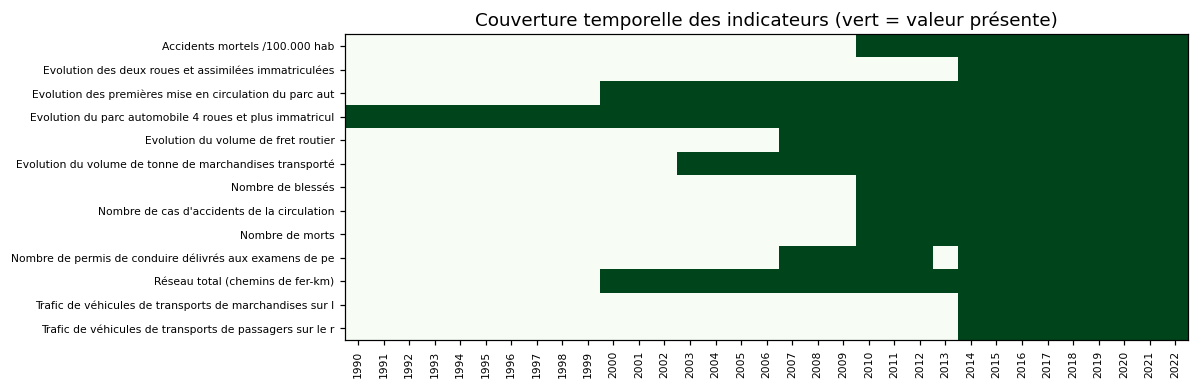

In [8]:
# Repérage des indicateurs utiles : parc, accidents, blessés, morts
KEY_RE = r"ACCIDENT|BLESS|MORT|DECES|TUE|PARC|VEHICULE|MOTO|IMMATRIC|CIRCUL"
key_ind = sorted([i for i in tt["indicateur"].dropna().unique() if re.search(KEY_RE, norm(i) or "")])
print(f"{len(key_ind)} indicateur(s) candidat(s) pour la sécurité routière / le parc :")
for i in key_ind:
    print("  •", i)

# Matrice de couverture (indicateur × année)
cov = tt.pivot_table(index="indicateur", columns="date_annee", values="value_num", aggfunc="size").notna()
fig, ax = plt.subplots(figsize=(11, max(3, .28 * len(cov))))
ax.imshow(cov.values, aspect="auto", cmap="Greens", vmin=0, vmax=1)
ax.set_yticks(range(len(cov))); ax.set_yticklabels([str(i)[:55] for i in cov.index], fontsize=7)
ax.set_xticks(range(len(cov.columns))); ax.set_xticklabels(cov.columns, rotation=90, fontsize=7)
ax.set_title("Couverture temporelle des indicateurs (vert = valeur présente)"); ax.grid(False)
plt.tight_layout(); plt.show()

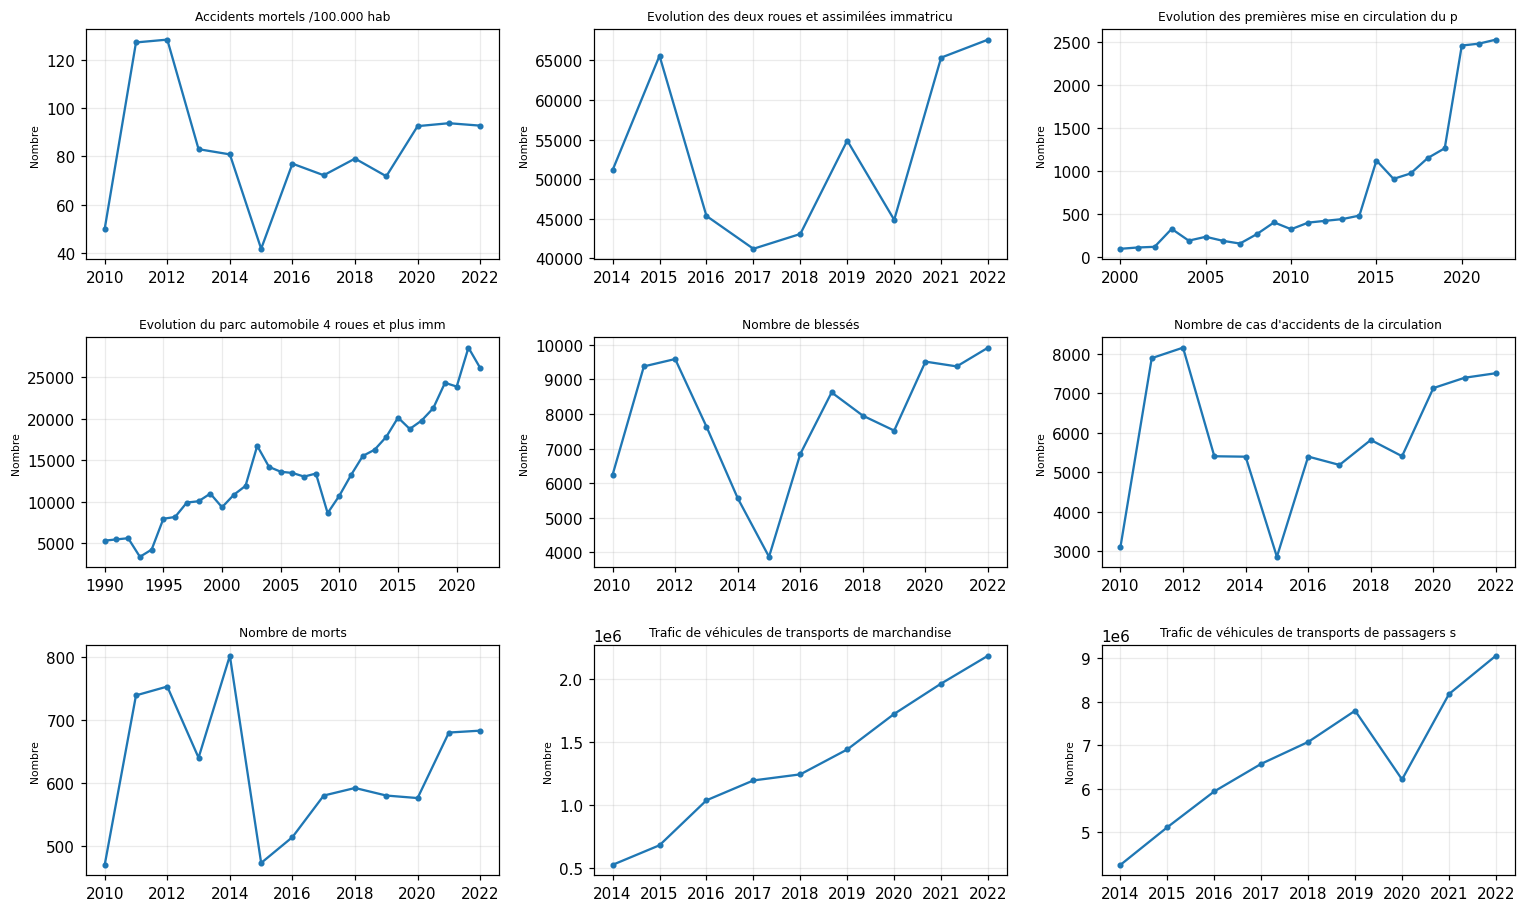

In [ ]:
# Courbes rapides des indicateurs candidats (limitées à 12 pour la lisibilité)
sel = key_ind[:12]
if sel:
    ncols = 3; nrows = int(np.ceil(len(sel) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 2.8 * nrows), squeeze=False)
    for ax, ind in zip(axes.ravel(), sel):
        d = tt[tt["indicateur"] == ind].sort_values("date_annee")
        ax.plot(d["date_annee"].astype(float), d["value_num"], marker="o", ms=3)
        ax.set_title(str(ind)[:48], fontsize=8)
        u = d["unit"].dropna().unique()
        ax.set_ylabel(str(u[0]) if len(u) else "", fontsize=7)
    for ax in axes.ravel()[len(sel):]:
        ax.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("Aucun indicateur candidat repéré : vérifier la liste du catalogue ci-dessus.")

**Diagnostic transports_terrestres.csv**   
 
Aucune valeur manquante ni de doublons. Les types de données sont corrrectes. Il n'est pas nécessaire de corriger ce dataset. 

## 2. permis_conduire  

Permis délivrés par catégorie et par année. La modalité **TOTAL** doit être isolée pour éviter tout double comptage.

**Description**  

Colonnes : indicateur (ici une seule indicateur ou modalité), categories-de-permis(attention cette variable contient une modalité TOTAL qui est le total de permis delivrés par année), Unit (ici unique : Nombre), Date( ce sont des années), Value

In [42]:
pc = std_cols(read_csv_robust(data_rep / FILES["permis"]))
need(pc, ["indicateur", "unit", "date", "value"], "permis_conduire")
overview(pc, "permis_conduire")
CAT_PC = get_cat_col(pc, "categories_de_permis", "permis_conduire")

pc["date_annee"] = to_year(pc["date"])
pc["value_num"] = check_value(pc, "permis_conduire")
print("Indicateur(s) :", pc["indicateur"].unique().tolist(), "| Unité(s) :", pc["unit"].unique().tolist())
print(f"Période : {pc['date_annee'].min()}–{pc['date_annee'].max()} ; années manquantes : {gaps(pc['date_annee']) or 'aucune'}")
display(pc[CAT_PC].value_counts(dropna=False).rename("n_lignes").to_frame())

dups = pc.duplicated([CAT_PC, "date_annee"], keep=False)
if dups.any():
    flag(f"permis_conduire : {int(dups.sum())} ligne(s) avec doublon (catégorie, année).")
cmp_pc = total_check(pc, CAT_PC, ["date_annee"], name="permis_conduire")
SUMMARY["permis_conduire"] = {"lignes": len(pc), "categories": int(pc[CAT_PC].nunique()),
                              "annees": f"{pc['date_annee'].min()}–{pc['date_annee'].max()}"}

Lecture de permis_conduire.csv : encodage=utf-8-sig, séparateur=','
=== permis_conduire : 106 lignes × 5 colonnes ===


,dtype,n_manquants,%_manquants,n_uniques
indicateur,object,0,0.0,1
categories_de_permis,object,0,0.0,7
unit,object,0,0.0,1
date,int64,0,0.0,16
value,int64,0,0.0,93


Lignes entièrement dupliquées : 0


,indicateur,categories_de_permis,unit,date,value
0,Nombre de permis de conduire délivrés par caté...,Moto (A),Nombre,2007,205
1,Nombre de permis de conduire délivrés par caté...,Moto (A),Nombre,2008,198
2,Nombre de permis de conduire délivrés par caté...,Moto (A),Nombre,2009,398
3,Nombre de permis de conduire délivrés par caté...,Moto (A),Nombre,2010,206
4,Nombre de permis de conduire délivrés par caté...,Moto (A),Nombre,2011,157


Indicateur(s) : ['Nombre de permis de conduire délivrés par catégorie aux examens de permis de conduire'] | Unité(s) : ['Nombre']
Période : 2007–2022 ; années manquantes : aucune


,n_lignes
categories_de_permis,
Total,16
Voiture légèr (B),15
Moto (A),15
Poids lourd (C),15
Transport en commun (D),15
Semi-remorque (E),15
Voiture spéciale (F),15


[permis_conduire] 16 groupe(s) contrôlé(s) ; 1 écart(s) entre somme des détails et TOTAL.
⚠️  permis_conduire : 1 groupe(s) où somme des détails ≠ TOTAL (voir tableau).


,somme_details,total_declare,n_lignes_total,ecart,ecart_%
date_annee,,,,,
2013,NaN,0,1,NaN,NaN


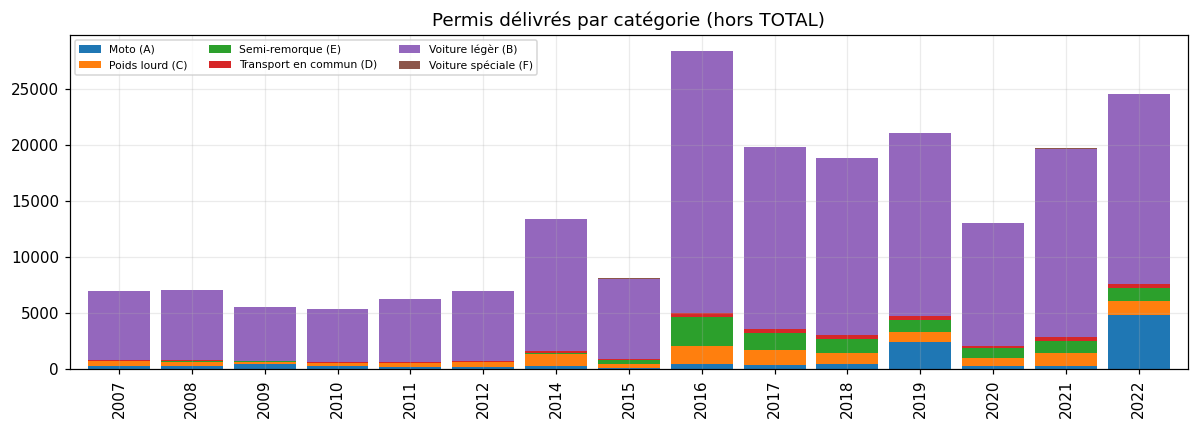

In [43]:
det = pc[pc[CAT_PC].map(lambda x: norm(x) != "TOTAL")].pivot_table(index="date_annee", columns=CAT_PC, values="value_num", aggfunc="sum")
fig, ax = plt.subplots(figsize=(11, 4))
det.plot(kind="bar", stacked=True, ax=ax, width=.85)
ax.set_title("Permis délivrés par catégorie (hors TOTAL)"); ax.set_xlabel(""); ax.legend(fontsize=7, ncol=3)
plt.tight_layout(); plt.show()

**Diagnostic permis_conduire.csv**   
 
Aucune valeur manquante ni de doublons. Les types de données sont corrrectes. Il n'est pas nécessaire de corriger ce dataset.   

Traitement : supprimer les lignes de Total.

## 3. immatriculations_2
Immatriculations par type de véhicule, avec une modalité **TOTAL**. D'après la description, la colonne `Date` n'est pas mentionnée : le notebook vérifie si elle existe.

**Description**  

indicateur(un seul), types-de-vehicule (attention, elle contient une modalité qui est le total par année), Unit (unique ici Nombre), Value

In [44]:
im2 = std_cols(read_csv_robust(data_rep / FILES["immat2"]))
need(im2, ["indicateur", "unit", "value"], "immatriculations_2")
overview(im2, "immatriculations_2")
CAT_IM2 = get_cat_col(im2, "types_de_vehicule", "immatriculations_2")
im2["value_num"] = check_value(im2, "immatriculations_2")

HAS_DATE_IM2 = "date" in im2.columns
if HAS_DATE_IM2:
    im2["date_annee"] = to_year(im2["date"])
    print(f"Période : {im2['date_annee'].min()}–{im2['date_annee'].max()} ; années manquantes : {gaps(im2['date_annee']) or 'aucune'}")
else:
    flag("immatriculations_2 : aucune colonne de date — impossible de situer les valeurs dans le temps (à vérifier avec la source).")

print("Indicateur(s) :", im2["indicateur"].unique().tolist(), "| Unité(s) :", im2["unit"].unique().tolist())
display(im2[CAT_IM2].value_counts(dropna=False).rename("n_lignes").to_frame())
cmp_im2 = total_check(im2, CAT_IM2, ["date_annee"] if HAS_DATE_IM2 else [], name="immatriculations_2")
SUMMARY["immatriculations_2"] = {"lignes": len(im2), "types_vehicule": int(im2[CAT_IM2].nunique()), "a_une_date": HAS_DATE_IM2}

Lecture de immatriculations_2.csv : encodage=utf-8-sig, séparateur=','
=== immatriculations_2 : 264 lignes × 5 colonnes ===


,dtype,n_manquants,%_manquants,n_uniques
indicateur,object,0,0.0,1
types_de_vehicule,object,0,0.0,8
unit,object,0,0.0,1
date,int64,0,0.0,33
value,int64,0,0.0,256


Lignes entièrement dupliquées : 0


,indicateur,types_de_vehicule,unit,date,value
0,Evolution du parc automobile immatriculé par t...,Voitures,Nombre,1990,3814
1,Evolution du parc automobile immatriculé par t...,Voitures,Nombre,1991,4004
2,Evolution du parc automobile immatriculé par t...,Voitures,Nombre,1992,4300
3,Evolution du parc automobile immatriculé par t...,Voitures,Nombre,1993,2577
4,Evolution du parc automobile immatriculé par t...,Voitures,Nombre,1994,3227


Période : 1990–2022 ; années manquantes : aucune
Indicateur(s) : ['Evolution du parc automobile immatriculé par type de véhicules'] | Unité(s) : ['Nombre']


,n_lignes
types_de_vehicule,
Voitures,33
Camionnettes,33
Autocars/Autobus,33
Camions,33
Semi-remorques,33
Tracteurs,33
2 R et Assimilées,33
Total,33


[immatriculations_2] 33 groupe(s) contrôlé(s) ; 0 écart(s) entre somme des détails et TOTAL.


**Diagnostic immatriculations_1.csv**   
 
Aucune valeur manquante ni de doublons. Les types de données sont corrrectes. Il n'est pas nécessaire de corriger ce dataset.   

Traitement : supprimer les lignes de Total.

## 4. immatriculations_1
Version à comparer avec `immatriculations_2`. La colonne nommée `automobile` semble porter le type de véhicule : le notebook affiche ses modalités pour le confirmer.

**Description**  

immatriculations_1.csv : moins détaillé que immatriculations_2.csv. 
colonnes: indicateur (un seul mm chose que immatriculations_2.csv), automobile, Unit, Date, Value

In [45]:
im1 = std_cols(read_csv_robust(data_rep / FILES["immat1"]))
need(im1, ["indicateur", "unit", "date", "value"], "immatriculations_1")
overview(im1, "immatriculations_1")
CAT_IM1 = get_cat_col(im1, "automobile", "immatriculations_1")
im1["date_annee"] = to_year(im1["date"])
im1["value_num"] = check_value(im1, "immatriculations_1")
print(f"Période : {im1['date_annee'].min()}–{im1['date_annee'].max()} ; années manquantes : {gaps(im1['date_annee']) or 'aucune'}")
print("Indicateur(s) :", im1["indicateur"].unique().tolist(), "| Unité(s) :", im1["unit"].unique().tolist())
display(im1[CAT_IM1].value_counts(dropna=False).rename("n_lignes").to_frame())

# Fréquence : y a-t-il plusieurs lignes par (catégorie, année) ? (ex. détail mensuel)
n_par = im1.groupby([CAT_IM1, "date_annee"]).size()
print(f"Lignes par (catégorie, année) : min={n_par.min()}, médiane={n_par.median()}, max={n_par.max()}")
if n_par.max() > 1:
    print("→ Plusieurs lignes par (catégorie, année) : granularité plus fine que l'année (à clarifier : mois ? sous-catégories ?).")
    display(im1.groupby([CAT_IM1, "date_annee"]).size().rename("n").reset_index().head(10))
cmp_im1 = total_check(im1, CAT_IM1, ["date_annee"], name="immatriculations_1")
SUMMARY["immatriculations_1"] = {"lignes": len(im1), "modalites_categorie": int(im1[CAT_IM1].nunique()),
                                 "annees": f"{im1['date_annee'].min()}–{im1['date_annee'].max()}"}

Lecture de immatriculations_1.csv : encodage=utf-8-sig, séparateur=','
=== immatriculations_1 : 70 lignes × 5 colonnes ===


,dtype,n_manquants,%_manquants,n_uniques
indicateur,object,0,0.0,1
automobile,object,0,0.0,10
unit,object,0,0.0,1
date,int64,0,0.0,7
value,int64,0,0.0,70


Lignes entièrement dupliquées : 0


,indicateur,automobile,unit,date,value
0,Evolution du parc automobile immatriculé par t...,Total 4 Roues,Nombre,2013,16273
1,Evolution du parc automobile immatriculé par t...,Total 4 Roues,Nombre,2014,17834
2,Evolution du parc automobile immatriculé par t...,Total 4 Roues,Nombre,2015,20149
3,Evolution du parc automobile immatriculé par t...,Total 4 Roues,Nombre,2016,18779
4,Evolution du parc automobile immatriculé par t...,Total 4 Roues,Nombre,2017,19782


Période : 2013–2019 ; années manquantes : aucune
Indicateur(s) : ['Evolution du parc automobile immatriculé par type de véhicules'] | Unité(s) : ['Nombre']


,n_lignes
automobile,
Total 4 Roues,7
Voitures,7
Camionnettes,7
Auto-cars,7
Camions,7
Semi-Remorques,7
Tract. Routiers,7
Total 2 Roues,7
Engins à 2 R de 50 à 125cm3,7


Lignes par (catégorie, année) : min=1, médiane=1.0, max=1
[immatriculations_1] aucune modalité TOTAL dans 'automobile'.


In [47]:
# Rapprochement immatriculations_1 / immatriculations_2 (total annuel)
if HAS_DATE_IM2:
    a = im1[im1[CAT_IM1].map(lambda x: norm(x) != "TOTAL")].groupby("date_annee")["value_num"].sum().rename("immat1_somme")
    b2 = im2[im2[CAT_IM2].map(lambda x: norm(x) == "TOTAL")].groupby("date_annee")["value_num"].first().rename("immat2_total")
    comp = pd.concat([a, b2], axis=1)
    comp["ratio_1_sur_2"] = (comp["immat1_somme"] / comp["immat2_total"]).round(3)
    display(comp)
    if comp["ratio_1_sur_2"].dropna().sub(1).abs().gt(.01).any():
        flag("immatriculations_1 vs immatriculations_2 : les totaux annuels diffèrent de plus de 1 % (voir tableau).")
else:
    print("Comparaison impossible tant que immatriculations_2 n'a pas de colonne de date.")

,immat1_somme,immat2_total,ratio_1_sur_2
date_annee,,,
2013,116206.0,58103,2.0
2014,137936.0,68968,2.0
2015,171496.0,85748,2.0
2016,128240.0,64120,2.0
2017,121938.0,60969,2.0
2018,128692.0,64346,2.0
2019,158428.0,79214,2.0
1990,NaN,6829,NaN
1991,NaN,7069,NaN


⚠️  immatriculations_1 vs immatriculations_2 : les totaux annuels diffèrent de plus de 1 % (voir tableau).


## 5. reseau_routier
Photographie 2020 de l'état du réseau par tronçon (BON, MOYEN, MAUVAIS, TRAVAUX). **Piège** : la modalité `TOTAL` de la colonne `troncon` répète, pour chaque état, le total des tronçons.

**Description**  

colonnes : indicateur (c'est d'autres indicateurs aussi), tronçon, etat, Unit, Date, Value.
Chaque indicateur se repètent autant de fois qu'il y a de tronçon. Mais attention il y a un piège ici qui ne faut pas surtout ignorée. en réalité la colonne tronçon contient une modalité TOTAL qui se répète pour chaque etat(BON, MOYEN, MAUVAIS, TRAVAUX) qui n'est que le total de chacque indicateur en fonction des tronçons qu'il a. On va devoir gérer cela lors de la correction des données. 
la colonne Date ne contient qu'une seule modalité (2020) ce qui veut que c'est uniquement les données de cette années. Value et Unit sont les meme que décrit précedement.

In [48]:
rr = std_cols(read_csv_robust(data_rep/ FILES["reseau"]))
need(rr, ["indicateur", "troncon", "etat", "unit", "date", "value"], "reseau_routier")
overview(rr, "reseau_routier")
rr["date_annee"] = to_year(rr["date"])
rr["value_num"] = check_value(rr, "reseau_routier")
print("Année(s) :", rr["date_annee"].dropna().unique().tolist())

display(rr.groupby(["indicateur", "unit"], dropna=False).size().rename("n_lignes").to_frame())
print("États présents :", rr["etat"].dropna().unique().tolist())
exp = {"BON", "MOYEN", "MAUVAIS", "TRAVAUX", "TOTAL"}
unexp = sorted({norm(e) for e in rr["etat"].dropna().unique()} - exp)
if unexp:
    flag(f"reseau_routier : états inattendus {unexp}")

is_tot = rr["troncon"].map(lambda x: norm(x) == "TOTAL")
print(f"Lignes TOTAL : {int(is_tot.sum())} / {len(rr)} ; tronçons distincts (hors TOTAL) : {rr.loc[~is_tot, 'troncon'].nunique()}")
d = rr.duplicated(["indicateur", "troncon", "etat"], keep=False)
if d.any():
    flag(f"reseau_routier : {int(d.sum())} ligne(s) avec doublon (indicateur, tronçon, état).")
cmp_rr = total_check(rr, "troncon", ["indicateur", "etat"], name="reseau_routier")
print("Exemples de noms de tronçons (pour le futur rattachement à routes_classees) :")
print(rr.loc[~is_tot, "troncon"].drop_duplicates().head(40).tolist())
SUMMARY["reseau_routier"] = {"lignes": len(rr), "troncons": int(rr.loc[~is_tot, "troncon"].nunique()),
                             "indicateurs": int(rr["indicateur"].nunique()), "annees": rr["date_annee"].dropna().unique().tolist()}

Lecture de reseau_routier.csv : encodage=utf-8-sig, séparateur=','
=== reseau_routier : 371 lignes × 6 colonnes ===


,dtype,n_manquants,%_manquants,n_uniques
indicateur,object,0,0.0,4
troncon,object,0,0.0,88
etat,object,0,0.0,5
unit,object,0,0.0,1
date,int64,0,0.0,1
value,float64,0,0.0,235


Lignes entièrement dupliquées : 0


,indicateur,troncon,etat,unit,date,value
0,ROUTES REVETUES,TOTAL,TOTAL,km,2020,2198.47
1,ROUTES REVETUES,TOTAL,BON,km,2020,754.16
2,ROUTES REVETUES,TOTAL,MOYEN,km,2020,431.84
3,ROUTES REVETUES,TOTAL,MAUVAIS,km,2020,562.74
4,ROUTES REVETUES,TOTAL,TRAVAUX,km,2020,449.74


Année(s) : [2020]


,,n_lignes
indicateur,unit,
ROUTES EN TERRES,km,141
ROUTES REVETUES,km,222
VOIRIES EN TERRES,km,4
VOIRIES REVETUES,km,4


États présents : ['TOTAL', 'BON', 'MOYEN', 'MAUVAIS', 'TRAVAUX']
Lignes TOTAL : 5 / 371 ; tronçons distincts (hors TOTAL) : 87
[reseau_routier] 18 groupe(s) contrôlé(s) ; 13 écart(s) entre somme des détails et TOTAL.
⚠️  reseau_routier : 13 groupe(s) où somme des détails ≠ TOTAL (voir tableau).


somme_details  total_declare  n_lignes_total  ecart  ecart_%
indicateur        etat                                                                 
ROUTES EN TERRES  BON             485.69            NaN             NaN    NaN      NaN
                  MAUVAIS         213.15            NaN             NaN    NaN      NaN
                  MOYEN           607.44            NaN             NaN    NaN      NaN
                  TOTAL          1929.93            NaN             NaN    NaN      NaN
                  TRAVAUX         623.64            NaN             NaN    NaN      NaN
VOIRIES EN TERRES BON              42.75            NaN             NaN    NaN      NaN
                  MAUVAIS           5.23            NaN             NaN    NaN      NaN
                  MOYEN            14.90            NaN             NaN    NaN      NaN
                  TOTAL            62.87            NaN             NaN    NaN      NaN
VOIRIES REVETUES  BON              33.00            NaN             NaN    NaN      NaN
                  MAUVAIS          24.62            NaN             NaN    NaN      NaN
                  MOYEN            18.90            NaN             NaN    NaN      NaN
                  TOTAL            76.52            NaN             NaN    NaN      NaN

Exemples de noms de tronçons (pour le futur rattachement à routes_classees) :
['LOME-AKOUMAPE-VOGAN-ANFOIN (RN4)', 'TSEVIE-TABLIGBO-ANFOIN-ANEHO', 'DAVIE-LOME (PASSAGE SUPERIEUR)', 'DAVIE-AMAKPAPE', 'RN2/3 AFLAO-HILACONDJI-FRT BENIN RETOUR (CARREFOUR AVEPOZO - FRT GHANA)', 'RN2/3 AFLAO-HILACONDJI-FRT BENIN RETOUR 2', 'RN2/3 AFLAO-HILACONDJI FRE BENIN', 'RN36 AMEGNRAN-AFAGNAN', 'RN36 ANEHO-AKLAKOU', 'RN5 LOME-AMOUZOU COPE', 'ALINMONDJI (RN1)-ELAVAGNON', 'AZANHOUN FIAGBE-PRESIDENT COPE', 'BRETELLE KOUGNOHOU(KOUGNOHOU-ADAPE(RN15))', 'RN33 AGOU GADJEPE(RN5)-AGOTIME-FRE GHANA', 'RN5-HOPITAL AGOU NYOGBO', 'ROUTE CAMPEMENT', 'ROUTE CHATEAU VIAL', 'RN1 AMAKPAPE-ATAKPAME- BABAME', 'RN11 KPALIME (RN5)-KPADAPE-FRE GHANA', 'RN11A KPADAPE-KLO MAYONDI-FRE GHANA', 'TGRPRRRN13 KPALIME(RN5)-MONT KLOTO-KAMETONOU-FRE GHANA', 'TGRPRRRN15 TEMEDJA(RN5)-BADOU-FRE GHANA', 'TGRPRRRN15A BADOU-REVIERE WAWA (FRE GHABA)', 'TGRPRRRN15B BADOU-TOMEGBE-FRE GHANA', 'TGRPRRRN30 ADETA(RN5)-NDIGBE-APEYEME-FRE GHANA', 'TGR

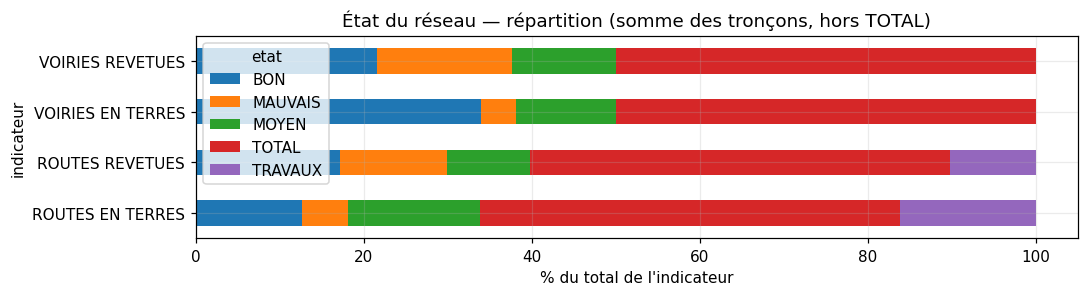

etat,BON,MAUVAIS,MOYEN,TOTAL,TRAVAUX
indicateur,,,,,
ROUTES EN TERRES,485.69,213.15,607.44,1929.93,623.64
ROUTES REVETUES,754.17,562.77,431.82,2198.52,449.75
VOIRIES EN TERRES,42.75,5.23,14.90,62.87,NaN
VOIRIES REVETUES,33.00,24.62,18.90,76.52,NaN


In [49]:
# Répartition par état à partir des lignes détaillées (hors TOTAL), par indicateur
det = rr[~is_tot].pivot_table(index="indicateur", columns="etat", values="value_num", aggfunc="sum")
if len(det):
    fig, ax = plt.subplots(figsize=(10, max(2.5, .7 * len(det))))
    (det.div(det.sum(axis=1), axis=0) * 100).plot(kind="barh", stacked=True, ax=ax)
    ax.set_xlabel("% du total de l'indicateur"); ax.set_title("État du réseau — répartition (somme des tronçons, hors TOTAL)")
    plt.tight_layout(); plt.show()
    display(det)

**Diagnostic reseau_routier.csv**   
 
Aucune valeur manquante ni de doublons. Les types de données sont corrrectes. Il n'est pas nécessaire de corriger ce dataset.   

Traitement : supprimer les lignes de Total.

## 6. routes_classees
Tracé du réseau classé. **Les géométries sont conservées telles quelles** (aucune simplification, aucune modification) : le notebook se contente de les lire et de les contrôler. Les longueurs sont calculées en projection métrique (EPSG:32631).

**Description**  

colonnes : FID (ça veut dire identifiant), region_nom_bdd (nom des régions), prefecture_nom_bdd(nom des préfectures dans la région,  commune_nom_bdd(nom commune dans la préfecture),  canton_nom_bdd(canton dans la préf), voies_nbr (nombre de voies), route_type, route_classee (une seule modalité qui est oui), route_recouvrement(plusieurs modalitées, c'est comme le type de route aussi sauf ici c'est le type de recouvrement par exemple Bitume, Terre aménagée, etc), geometry(le type est <class 'pandas.core.series.Series'>)  et enfin la variable route_nom (nom de la route)

In [50]:
ro = std_cols(read_csv_robust(data_rep / FILES["routes"]))
need(ro, ["fid", "region_nom_bdd", "prefecture_nom_bdd", "commune_nom_bdd", "canton_nom_bdd",
          "voies_nbr", "route_type", "route_classee", "route_recouvrement", "geometry", "route_nom"], "routes_classees")
overview(ro, "routes_classees (avant lecture des géométries)", n=3)

print("FID unique ?", ro["fid"].is_unique, "| valeurs manquantes FID :", int(ro["fid"].isna().sum()))
if not ro["fid"].is_unique:
    flag("routes_classees : FID non unique.")
print("route_classee :", ro["route_classee"].value_counts(dropna=False).to_dict())
for c in ["voies_nbr", "route_type", "route_recouvrement"]:
    print(f"\n--- {c} ---")
    display(ro[c].value_counts(dropna=False).rename("n").to_frame())

Lecture de routes_classees.csv : encodage=utf-8-sig, séparateur=','
=== routes_classees (avant lecture des géométries) : 799 lignes × 11 colonnes ===


,dtype,n_manquants,%_manquants,n_uniques
fid,object,0,0.00,799
region_nom_bdd,object,0,0.00,5
prefecture_nom_bdd,object,0,0.00,38
commune_nom_bdd,object,0,0.00,102
canton_nom_bdd,object,0,0.00,244
voies_nbr,int64,0,0.00,5
route_type,object,0,0.00,4
route_classee,object,0,0.00,1
route_recouvrement,object,0,0.00,7
geometry,object,0,0.00,799


Lignes entièrement dupliquées : 0


,fid,region_nom_bdd,prefecture_nom_bdd,commune_nom_bdd,canton_nom_bdd,voies_nbr,route_type,route_classee,route_recouvrement,geometry,route_nom
0,_mview_route_routes.fid--830921d_193db4998a0_759a,Kara,Assoli,Assoli 1,Bafilo,1,Route nationale non revêtue,Oui,Terre amenagée,MULTILINESTRING ((1.243850877516584 9.35150743...,TGRKRTRN38 RN1 BAFILO-DAKO-RN17 BASSAR
1,_mview_route_routes.fid--830921d_193db4998a0_759b,Kara,Assoli,Assoli 1,Bouladè,2,Route nationale revêtue,Oui,Bitume,MULTILINESTRING ((1.2130456942960375 9.4373636...,TGRKRR RN1 ALEHERIDE-KARA-NABLOUGOU
2,_mview_route_routes.fid--830921d_193db4998a0_759c,Plateaux,Wawa,Wawa 3,Klabé-Efoukpa,1,Route nationale non revêtue,Oui,Terre non amenagée,MULTILINESTRING ((0.8539900000000001 7.6305800...,TGRPRTRN15BIS HIHIATRO(RN5)-KLABE-APEGANME-KOU...


FID unique ? True | valeurs manquantes FID : 0
route_classee : {'Oui': 799}

--- voies_nbr ---


,n
voies_nbr,
2,547
1,225
3,15
0,8
4,4



--- route_type ---


,n
route_type,
Route nationale revêtue,398
Route nationale non revêtue,196
Voirie urbaine,192
Piste rurale,13



--- route_recouvrement ---


,n
route_recouvrement,
Bitume,445
Terre amenagée,176
Terre non amenagée,154
Beton,12
Gravier non amenagé,5
Pavé,5
Gravier amenagé,2


In [51]:
# Lecture des géométries (WKT -> objets shapely) sans aucune transformation
ro["geometry"] = ro["geometry"].apply(parse_wkt)
n_bad = int(ro["geometry"].isna().sum())
if n_bad:
    flag(f"routes_classees : {n_bad} géométrie(s) manquante(s) ou illisible(s).")
gro = gpd.GeoDataFrame(ro, geometry="geometry", crs=CRS_GEO)

print("Types de géométrie :", gro.geometry.geom_type.value_counts(dropna=False).to_dict())
print("Géométries vides   :", int(gro.geometry.is_empty.sum()), "| invalides :", int((~gro.geometry.is_valid).sum()))

# Plausibilité des coordonnées (ordre lon/lat, emprise Togo)
minx, miny, maxx, maxy = gro.total_bounds
print(f"Emprise : lon [{minx:.4f}, {maxx:.4f}] · lat [{miny:.4f}, {maxy:.4f}]")
bx0, by0, bx1, by1 = TOGO_BBOX
if minx < bx0 or maxx > bx1 or miny < by0 or maxy > by1:
    flag("routes_classees : coordonnées hors de l'emprise attendue du Togo (inversion lon/lat ? autre CRS ?).")

def n_vertices(g):
    if g is None or g.is_empty:
        return 0
    parts = g.geoms if hasattr(g, "geoms") else [g]
    return int(sum(len(p.coords) for p in parts))

def n_consec_dups(g):
    # Compte (à titre d'information) les sommets consécutifs identiques ; la géométrie n'est PAS modifiée.
    if g is None or g.is_empty:
        return 0
    parts = g.geoms if hasattr(g, "geoms") else [g]
    k = 0
    for p in parts:
        c = np.asarray(p.coords)[:, :2]
        k += int(np.all(c[1:] == c[:-1], axis=1).sum())
    return k

gro["n_sommets"] = gro.geometry.apply(n_vertices)
gro["n_sommets_dupliques"] = gro.geometry.apply(n_consec_dups)
gro["n_parties"] = gro.geometry.apply(lambda g: len(g.geoms) if g is not None and hasattr(g, "geoms") else 1)
print(f"\nSommets par ligne : médiane={gro['n_sommets'].median():.0f}, max={gro['n_sommets'].max()}, total={gro['n_sommets'].sum():,}")
print(f"Sommets consécutifs dupliqués (info) : {gro['n_sommets_dupliques'].sum():,} "
      f"({100 * gro['n_sommets_dupliques'].sum() / max(gro['n_sommets'].sum(), 1):.1f} % des sommets)")
print("Lignes multi-parties :", int((gro["n_parties"] > 1).sum()))

Types de géométrie : {'MultiLineString': 799}
Géométries vides   : 0 | invalides : 0
Emprise : lon [0.0085, 1.7657] · lat [6.1135, 11.1138]

Sommets par ligne : médiane=70, max=1811, total=150,582
Sommets consécutifs dupliqués (info) : 29,708 (19.7 % des sommets)
Lignes multi-parties : 8


In [52]:
# Longueurs en km (projection métrique ; la géométrie d'origine reste inchangée)
gro["longueur_km"] = gro.to_crs(CRS_PROJ).geometry.length / 1000
print(f"Longueur totale du réseau classé : {gro['longueur_km'].sum():,.1f} km ; {int((gro['longueur_km'] == 0).sum())} ligne(s) de longueur nulle")
if (gro["longueur_km"] == 0).any():
    flag("routes_classees : lignes de longueur nulle.")

def long_by(col):
    t = (gro.groupby(col, dropna=False)
            .agg(n_troncons=("fid", "size"), longueur_km=("longueur_km", "sum"))
            .sort_values("longueur_km", ascending=False))
    t["%_longueur"] = (100 * t["longueur_km"] / t["longueur_km"].sum()).round(2)
    return t.round(2)

for c in ["region_nom_bdd", "route_recouvrement", "route_type", "voies_nbr"]:
    print(f"\n--- Longueur par {c} ---")
    display(long_by(c))
print("\n--- 15 routes les plus longues (par nom) ---")
display(gro.groupby("route_nom", dropna=False)["longueur_km"].sum().sort_values(ascending=False).head(15).round(1).to_frame())

# Cohérence hiérarchique : une préfecture doit appartenir à une seule région
h = gro.groupby("prefecture_nom_bdd")["region_nom_bdd"].nunique()
if (h > 1).any():
    flag(f"routes_classees : préfecture(s) rattachée(s) à plusieurs régions : {list(h[h > 1].index)}")
miss_geo = gro[["region_nom_bdd", "prefecture_nom_bdd", "commune_nom_bdd", "canton_nom_bdd"]].isna().sum()
print("\nValeurs manquantes dans le découpage administratif :", miss_geo.to_dict())
SUMMARY["routes_classees"] = {"lignes": len(gro), "longueur_km": round(float(gro["longueur_km"].sum()), 1),
                              "regions": int(gro["region_nom_bdd"].nunique()), "prefectures": int(gro["prefecture_nom_bdd"].nunique()),
                              "types_geometrie": gro.geometry.geom_type.value_counts().to_dict()}

Longueur totale du réseau classé : 3,366.5 km ; 0 ligne(s) de longueur nulle

--- Longueur par region_nom_bdd ---


,n_troncons,longueur_km,%_longueur
region_nom_bdd,,,
Plateaux,321,1008.43,29.95
Kara,169,733.38,21.78
Maritime,153,636.10,18.90
Savanes,75,529.45,15.73
Centrale,81,459.13,13.64



--- Longueur par route_recouvrement ---


,n_troncons,longueur_km,%_longueur
route_recouvrement,,,
Bitume,445,2173.54,64.56
Terre amenagée,176,765.27,22.73
Terre non amenagée,154,414.05,12.30
Beton,12,5.76,0.17
Gravier non amenagé,5,5.69,0.17
Pavé,5,1.14,0.03
Gravier amenagé,2,1.04,0.03



--- Longueur par route_type ---


...


--- Longueur par voies_nbr ---


,n_troncons,longueur_km,%_longueur
voies_nbr,,,
2,547,2618.75,77.79
1,225,635.60,18.88
0,8,39.36,1.17
3,15,36.52,1.08
4,4,36.25,1.08



--- 15 routes les plus longues (par nom) ---


,longueur_km
route_nom,
TGRSRRRN1 NABOULGOU-DAPAONG-CINKASSE-FRE BURKINA,159.8
TGRPRRRN5 ATAKPAME-KPALIME-AMOUSSOUKOPE,142.5
TGRPRRRN1 AMAKPAPE-ATAKPAME-BABAME,140.7
TGRKRR RN1 ALEHERIDE-KARA-NABLOUGOU,129.4
TGRCRRRN1 BABAME-SOKODE-ALEHERIDE,128.8
TGRCRTRN12 SOTOUBOUA-GOUBI-KABOLI,97.8
TGRPRRRN15 TEMEDJA(RN5)-BADOU-FRE GHANA,88.3
TGRMRRRN4 TSEVIE-TABLIGBO-ANEHO,85.9
TGRCRRRN14 SOKODE-TCHAMBA-KABOLI-FRE BENIN,85.3



Valeurs manquantes dans le découpage administratif : {'region_nom_bdd': 0, 'prefecture_nom_bdd': 0, 'commune_nom_bdd': 0, 'canton_nom_bdd': 0}


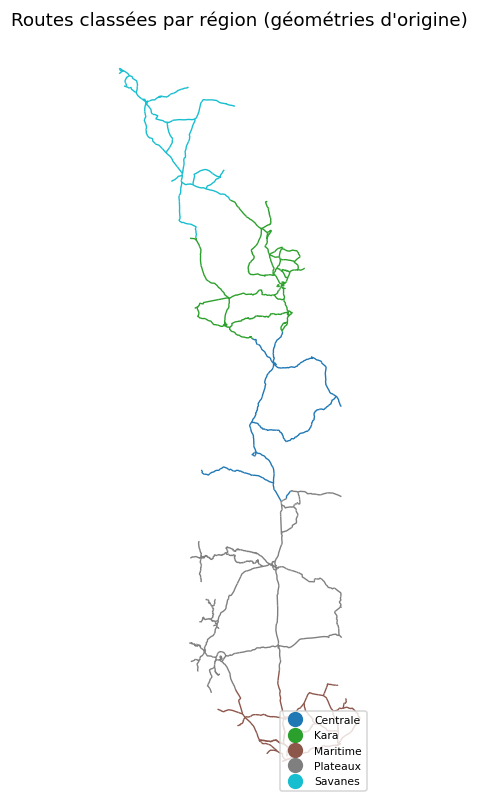

In [53]:
# Carte d'exploration : tracé réel (non simplifié) coloré par région
fig, ax = plt.subplots(figsize=(6, 9))
gro.plot(ax=ax, column="region_nom_bdd", categorical=True, legend=True, linewidth=.9,
         legend_kwds={"fontsize": 7, "loc": "lower right"})
ax.set_title("Routes classées par région (géométries d'origine)"); ax.set_axis_off()
plt.show()

**Diagnostic routes_classees.csv**   
 
Aucune valeur manquante ni de doublons. Les types de données sont corrrectes. Il n'est pas nécessaire de corriger ce dataset.   

## 7. entreprises_auto_ecoles
Points d'implantation des auto-écoles. Contrôles : géométrie POINT, emprise, doublons de lieu ou de nom, contenu de `journee_ouverture` (liste) et de `agregation`.

**Description**  

entreprises_auto_ecoles.csv
Colonnes: FID, region_nom_bdd, prefecture_nom_bdd, commune_nom_bdd, canton_nom_bdd, nom_localite, nom_etablissement, journee_ouverture(une liste), actuvite_categorie(une seule modalité), geometrie (exemple: POINT (1.1381004717211132 8.9831547852801)), agregation (plusieurs modalites)

In [54]:
ae = std_cols(read_csv_robust(data_rep / FILES["autoecoles"]))
need(ae, ["fid", "region_nom_bdd", "prefecture_nom_bdd", "commune_nom_bdd", "canton_nom_bdd",
          "nom_localite", "nom_etablissement", "journee_ouverture", "actuvite_categorie", "geometrie", "agregation"], "entreprises_auto_ecoles")
overview(ae, "entreprises_auto_ecoles", n=3)
print("FID unique ?", ae["fid"].is_unique)
if not ae["fid"].is_unique:
    flag("entreprises_auto_ecoles : FID non unique.")
print("activite_categorie :", ae["activite_categorie"].value_counts(dropna=False).to_dict())
print("\n--- agregation ---")
display(ae["agregation"].value_counts(dropna=False).rename("n").to_frame())

Lecture de entreprises_auto_ecoles.csv : encodage=utf-8-sig, séparateur=','
⚠️  entreprises_auto_ecoles : colonnes attendues introuvables ['actuvite_categorie', 'geometrie']. Colonnes disponibles : ['fid', 'region_nom_bdd', 'prefecture_nom_bdd', 'commune_nom_bdd', 'canton_nom_bdd', 'nom_localite', 'nom_etablissement', 'adresse_etablissement', 'journee_ouverture', 'activite_categorie', 'geometry', 'agregation']
=== entreprises_auto_ecoles : 272 lignes × 12 colonnes ===


,dtype,n_manquants,%_manquants,n_uniques
fid,object,0,0.0,272
region_nom_bdd,object,0,0.0,5
prefecture_nom_bdd,object,0,0.0,24
commune_nom_bdd,object,0,0.0,40
canton_nom_bdd,object,0,0.0,42
nom_localite,object,0,0.0,194
nom_etablissement,object,0,0.0,272
adresse_etablissement,object,0,0.0,102
journee_ouverture,object,0,0.0,20
activite_categorie,object,0,0.0,1


Lignes entièrement dupliquées : 0


,fid,region_nom_bdd,prefecture_nom_bdd,commune_nom_bdd,canton_nom_bdd,nom_localite,nom_etablissement,adresse_etablissement,journee_ouverture,activite_categorie,geometry,agregation
0,_mview_entreprisesvariees_entreprises_variees....,Centrale,Tchaoudjo,Tchaoudjo 1,Sokodè (Komah),Didaure,Auto-école Nouvelle,Nsp,"{lundi,mardi,mercredi,jeudi,vendredi,samedi}",{Auto-école},POINT (1.1381004717211132 8.9831547852801),Agréée
1,_mview_entreprisesvariees_entreprises_variees....,Centrale,Blitta,Blitta 1,Pagala-Gare,Pagala Gare,Auto-école la Prudence Pagala Gare,Nsp,"{lundi,mardi,mercredi,jeudi,vendredi,samedi}",{Auto-école},POINT (0.9880383333333334 8.177550000000002),Non agréée
2,_mview_entreprisesvariees_entreprises_variees....,Centrale,Blitta,Blitta 1,Blitta,Blitta Dépôt,Auto-école la Nouvelle Blitta,BP 09 Blitta,"{mardi,mercredi,jeudi,vendredi,samedi,dimanche}",{Auto-école},POINT (0.9829727215157458 8.328168710609889),Non agréée


FID unique ? True
activite_categorie : {'{Auto-école}': 272}

--- agregation ---


,n
agregation,
Non agréée,138
Agréée,85
Antenne agréée,47
Néant,2


In [55]:
ae["geometry"] = ae["geometry"].apply(parse_wkt)
if ae["geometry"].isna().any():
    flag(f"entreprises_auto_ecoles : {int(ae['geometry'].isna().sum())} géométrie(s) manquante(s) ou illisible(s).")
gae = gpd.GeoDataFrame(ae, geometry="geometry", crs=CRS_GEO)
print("Types de géométrie :", gae.geometry.geom_type.value_counts(dropna=False).to_dict())
minx, miny, maxx, maxy = gae.total_bounds
print(f"Emprise : lon [{minx:.4f}, {maxx:.4f}] · lat [{miny:.4f}, {maxy:.4f}]")
bx0, by0, bx1, by1 = TOGO_BBOX
out = gae[~gae.geometry.is_empty & ((gae.geometry.x < bx0) | (gae.geometry.x > bx1) | (gae.geometry.y < by0) | (gae.geometry.y > by1))]
if len(out):
    flag(f"entreprises_auto_ecoles : {len(out)} point(s) hors de l'emprise du Togo.")
    display(out[["fid", "nom_etablissement", "region_nom_bdd"]].head(10))

# Doublons métier : même établissement (nom normalisé) ou mêmes coordonnées
gae["_nom_norm"] = gae["nom_etablissement"].map(norm)
gae["_xy"] = gae.geometry.apply(lambda g: (round(g.x, 6), round(g.y, 6)) if g is not None and not g.is_empty else None)
d_nom = gae.duplicated(["_nom_norm", "commune_nom_bdd"], keep=False) & gae["_nom_norm"].notna()
d_xy = gae.duplicated("_xy", keep=False) & gae["_xy"].notna()
print(f"Même nom + même commune : {int(d_nom.sum())} ligne(s) | mêmes coordonnées : {int(d_xy.sum())} ligne(s)")
if d_nom.any():
    flag(f"entreprises_auto_ecoles : {int(d_nom.sum())} ligne(s) avec même nom d'établissement dans la même commune (doublons probables).")
    display(gae.loc[d_nom, ["fid", "nom_etablissement", "commune_nom_bdd"]].sort_values("nom_etablissement").head(15))
if d_xy.any():
    flag(f"entreprises_auto_ecoles : {int(d_xy.sum())} ligne(s) partageant exactement les mêmes coordonnées.")

# Jours d'ouverture : lecture de la liste
def parse_list(x):
    if isinstance(x, (list, tuple)):
        return list(x)
    if pd.isna(x):
        return []
    s = str(x).strip()
    if s.startswith("["):
        try:
            return list(ast.literal_eval(s))
        except Exception:
            pass
    return [p.strip() for p in re.split(r"[;,|]", s.strip("[]")) if p.strip()]

jours = gae["journee_ouverture"].apply(parse_list)
gae["n_jours_ouverture"] = jours.apply(len)
print("\nExemples bruts de journee_ouverture :", gae["journee_ouverture"].dropna().head(3).tolist())
print("Nombre de jours d'ouverture (répartition) :", gae["n_jours_ouverture"].value_counts().sort_index().to_dict())
freq = pd.Series([norm(j) for l in jours for j in l]).value_counts()
display(freq.rename("n").to_frame())

for lvl in ["region_nom_bdd", "prefecture_nom_bdd"]:
    print(f"\n--- Auto-écoles par {lvl.replace('_nom_bdd', '')} ---")
    display(gae[lvl].value_counts(dropna=False).rename("n_auto_ecoles").to_frame())
SUMMARY["auto_ecoles"] = {"lignes": len(gae), "regions": int(gae["region_nom_bdd"].nunique()),
                          "prefectures": int(gae["prefecture_nom_bdd"].nunique())}

Types de géométrie : {'Point': 272}
Emprise : lon [0.0080, 1.7121] · lat [6.1264, 11.1000]
Même nom + même commune : 2 ligne(s) | mêmes coordonnées : 0 ligne(s)
⚠️  entreprises_auto_ecoles : 2 ligne(s) avec même nom d'établissement dans la même commune (doublons probables).


,fid,nom_etablissement,commune_nom_bdd
202,_mview_entreprisesvariees_entreprises_variees....,Auto-école Mega Succes,Agoè-Nyivé 5
111,_mview_entreprisesvariees_entreprises_variees....,Auto-école Mega Succès,Agoè-Nyivé 5



Exemples bruts de journee_ouverture : ['{lundi,mardi,mercredi,jeudi,vendredi,samedi}', '{lundi,mardi,mercredi,jeudi,vendredi,samedi}', '{mardi,mercredi,jeudi,vendredi,samedi,dimanche}']
Nombre de jours d'ouverture (répartition) : {1: 16, 4: 1, 5: 55, 6: 194, 7: 6}


,n
MERCREDI,254
MARDI,253
VENDREDI},171
{JEUDI,161
LUNDI,158
SAMEDI,133
JEUDI,93
{LUNDI,82
VENDREDI,81
SAMEDI},66



--- Auto-écoles par region ---


,n_auto_ecoles
region_nom_bdd,
Maritime,224
Kara,14
Centrale,12
Plateaux,12
Savanes,10



--- Auto-écoles par prefecture ---


,n_auto_ecoles
prefecture_nom_bdd,
Golfe,142
Agoè-Nyivé,71
Kozah,11
Lacs,5
Tône,5
Tchaoudjo,4
Sotouboua,4
Kloto,3
Oti,3


**Diagnostic entreprises_auto_ecoles.csv**   
 
Aucune valeur manquante ni de doublons. Les types de données sont corrrectes. Il n'est pas nécessaire de corriger ce dataset.   

entreprises_auto_ecoles : 2 ligne(s) avec même nom d'établissement dans la même commune (doublons probables).

## 8. pop_rgph5_tg
Population du RGPH-5 par canton (noms en majuscules, orthographes parfois différentes des autres sources).

In [56]:
pop = std_cols(read_csv_robust(data_rep/ FILES["pop"]))
need(pop, ["region_nom_bdd", "prefecture_nom_bdd", "commune_nom_bdd", "canton_nom_bdd", "population"], "pop_rgph5_tg")
overview(pop, "pop_rgph5_tg")
pop["population_num"] = check_value(pop, "pop_rgph5_tg", col="population")
print(f"Population totale : {pop['population_num'].sum():,.0f}")
print(f"Population min / médiane / max par ligne : {pop['population_num'].min():,.0f} / {pop['population_num'].median():,.0f} / {pop['population_num'].max():,.0f}")
if (pop["population_num"] <= 0).any():
    flag(f"pop_rgph5_tg : {int((pop['population_num'] <= 0).sum())} ligne(s) avec population nulle ou négative.")

keys = ["region_nom_bdd", "prefecture_nom_bdd", "commune_nom_bdd", "canton_nom_bdd"]
pk = pop.assign(**{c: pop[c].map(norm) for c in keys})
d = pk.duplicated(keys, keep=False)
if d.any():
    flag(f"pop_rgph5_tg : {int(d.sum())} ligne(s) avec même (région, préfecture, commune, canton) après normalisation.")
    display(pop.loc[d, keys + ["population_num"]].head(15))
h = pk.groupby("prefecture_nom_bdd")["region_nom_bdd"].nunique()
if (h > 1).any():
    flag(f"pop_rgph5_tg : préfecture(s) rattachée(s) à plusieurs régions : {list(h[h > 1].index)}")

for lvl in ["region_nom_bdd", "prefecture_nom_bdd"]:
    t = pop.groupby(lvl)["population_num"].sum().sort_values(ascending=False)
    print(f"\n--- Population par {lvl.replace('_nom_bdd', '')} ({len(t)} unités) ---")
    display(t.to_frame("population").assign(**{"%": (100 * t / t.sum()).round(2)}))
SUMMARY["pop_rgph5_tg"] = {"lignes": len(pop), "population_totale": int(pop["population_num"].sum()),
                           "regions": int(pop["region_nom_bdd"].nunique()), "prefectures": int(pop["prefecture_nom_bdd"].nunique())}

Lecture de pop_rgph5_tg.csv : encodage=utf-8-sig, séparateur=','
=== pop_rgph5_tg : 597 lignes × 5 colonnes ===


,dtype,n_manquants,%_manquants,n_uniques
region_nom_bdd,object,0,0.0,6
prefecture_nom_bdd,object,0,0.0,39
commune_nom_bdd,object,0,0.0,116
canton_nom_bdd,object,0,0.0,590
population,int64,0,0.0,588


Lignes entièrement dupliquées : 0


,region_nom_bdd,prefecture_nom_bdd,commune_nom_bdd,canton_nom_bdd,population
0,GRAND LOME,GOLFE,GOLFE 1,BE,10815
1,GRAND LOME,GOLFE,GOLFE 1,GBENYEDJI,11299
2,GRAND LOME,GOLFE,GOLFE 1,WETE,11088
3,GRAND LOME,GOLFE,GOLFE 1,BE HEDJE,11686
4,GRAND LOME,GOLFE,GOLFE 1,N'TIFAFA KOME,4539


Population totale : 8,095,498
Population min / médiane / max par ligne : 132 / 9,361 / 161,176

--- Population par region (6 unités) ---


,population,%
region_nom_bdd,,
GRAND LOME,2188376,27.03
PLATEAUX,1635946,20.21
MARITIME,1346615,16.63
SAVANES,1143520,14.13
KARA,985512,12.17
CENTRALE,795529,9.83



--- Population par prefecture (39 unités) ---


,population,%
prefecture_nom_bdd,,
GOLFE,1305681,16.13
AGOE-NYIVE,882695,10.90
ZIO,500032,6.18
TONE,388775,4.80
HAHO,305096,3.77
KOZAH,283738,3.50
OGOU,253467,3.13
LACS,241247,2.98
TCHAOUDJO,240360,2.97


## 9. Limites administratives (GeoJSON)
Fonds de carte régions et préfectures. Le notebook détecte automatiquement la colonne de noms en cherchant celle qui recoupe le mieux les noms de `pop_rgph5_tg`.

[régions] 5 entité(s) | CRS = EPSG:4326 | géométries : {'MultiPolygon': 5}


,GID_1,GID_0,COUNTRY,NAME_1,VARNAME_1,NL_NAME_1,TYPE_1,ENGTYPE_1,CC_1,HASC_1,ISO_1
0,TGO.1_1,TGO,Togo,Centre,"RégionCentrale,RégionduCentr",NA,Région,Region,NA,TG.CE,NA
1,TGO.2_1,TGO,Togo,Kara,RégiondelaKara,NA,Région,Region,NA,TG.KA,TG-K
2,TGO.3_1,TGO,Togo,Maritime,RégionMaritime,NA,Région,Region,NA,TG.MA,TG-M
3,TGO.4_1,TGO,Togo,Plateaux,RégiondesPlateaux,NA,Région,Region,NA,TG.PL,TG-P
4,TGO.5_1,TGO,Togo,Savanes,RégiondesSavanes,NA,Région,Region,NA,TG.SA,TG-S


[préfectures] 40 entité(s) | CRS = EPSG:4326 | géométries : {'MultiPolygon': 40}


,GID_2,GID_0,COUNTRY,GID_1,NAME_1,NL_NAME_1,NAME_2,VARNAME_2,NL_NAME_2,TYPE_2,ENGTYPE_2,CC_2,HASC_2
0,TGO.1.1_2,TGO,Togo,TGO.1_1,Centre,NA,Blitta,NA,NA,Préfecture,Prefecture,NA,TG.CE.BL
1,TGO.1.2_2,TGO,Togo,TGO.1_1,Centre,NA,Mô,NA,NA,Sous-Préfecture,Sub-Prefecture,NA,NA
2,TGO.1.3_2,TGO,Togo,TGO.1_1,Centre,NA,Sotouboua,NA,NA,Préfecture,Prefecture,NA,TG.CE.SO
3,TGO.1.4_2,TGO,Togo,TGO.1_1,Centre,NA,Tchamba,Nyala|Tchamba,NA,Préfecture,Prefecture,NA,TG.CE.TB
4,TGO.1.5_2,TGO,Togo,TGO.1_1,Centre,NA,Tchaudjo,Sokodé|Tchaoudjo,NA,Préfecture,Prefecture,NA,TG.CE.TD


[régions] colonne de noms retenue : 'NAME_1' (4 nom(s) en commun avec pop_rgph5_tg sur 6)
[préfectures] colonne de noms retenue : 'NAME_2' (35 nom(s) en commun avec pop_rgph5_tg sur 39)

Validité des polygones de régions : 0 invalide(s)
Validité des polygones de préfectures : 0 invalide(s)


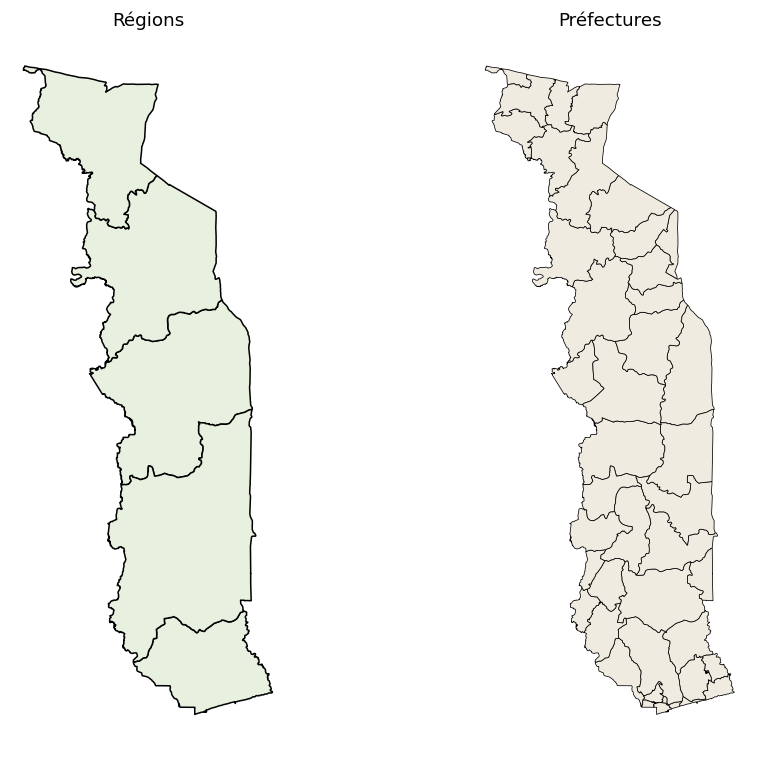

In [57]:
def load_admin(path, label):
    path = Path(path)
    if not path.exists():
        print(f"[{label}] fichier introuvable : {path} (adapter GEOJSON_* à l'étape 0)")
        return None
    g = gpd.read_file(path)
    print(f"[{label}] {len(g)} entité(s) | CRS = {g.crs} | géométries : {g.geometry.geom_type.value_counts().to_dict()}")
    if g.crs is None:
        flag(f"{label} : CRS absent du GeoJSON (supposé EPSG:4326).")
        g = g.set_crs(CRS_GEO)
    elif g.crs.to_string() != CRS_GEO:
        print(f"[{label}] reprojection vers {CRS_GEO}")
        g = g.to_crs(CRS_GEO)
    display(g.drop(columns="geometry").head(5))
    return g

def best_name_col(g, ref_names, label):
    ref = {norm(x) for x in ref_names if pd.notna(x)}
    best, best_n = None, -1
    for c in g.columns:
        if c == "geometry" or not (g[c].dtype == object or pd.api.types.is_string_dtype(g[c])):
            continue
        n = len({norm(v) for v in g[c].dropna()} & ref)
        if n > best_n:
            best, best_n = c, n
    print(f"[{label}] colonne de noms retenue : {best!r} ({best_n} nom(s) en commun avec pop_rgph5_tg sur {len(ref)})")
    return best

adm_reg = load_admin(GEOJSON_REGIONS, "régions")
adm_pref = load_admin(GEOJSON_PREFECTURES, "préfectures")
REG_COL = best_name_col(adm_reg, pop["region_nom_bdd"], "régions") if adm_reg is not None else None
PREF_COL = best_name_col(adm_pref, pop["prefecture_nom_bdd"], "préfectures") if adm_pref is not None else None

if adm_reg is not None:
    print("\nValidité des polygones de régions :", int((~adm_reg.geometry.is_valid).sum()), "invalide(s)")
if adm_pref is not None:
    print("Validité des polygones de préfectures :", int((~adm_pref.geometry.is_valid).sum()), "invalide(s)")
    if adm_reg is not None:
        fig, axes = plt.subplots(1, 2, figsize=(10, 7))
        adm_reg.plot(ax=axes[0], edgecolor="k", facecolor="#e8f0e0"); axes[0].set_title("Régions")
        adm_pref.plot(ax=axes[1], edgecolor="k", facecolor="#f0ebe0", linewidth=.5); axes[1].set_title("Préfectures")
        for a in axes: a.set_axis_off()
        plt.tight_layout(); plt.show()
SUMMARY["geojson"] = {"regions": None if adm_reg is None else len(adm_reg),
                      "prefectures": None if adm_pref is None else len(adm_pref),
                      "col_noms_regions": REG_COL, "col_noms_prefectures": PREF_COL}

## 10. Contrôles croisés
Deux questions : (1) les noms géographiques se rejoignent-ils entre sources ? (2) les périodes couvertes sont-elles compatibles ?

In [58]:
def compare_keys(df_a, df_b, cols, na, nb, show=12):
    ka, kb = keyset(df_a, cols), keyset(df_b, cols)
    inter = ka & kb
    print(f"  {na}: {len(ka)} clés | {nb}: {len(kb)} clés | communes: {len(inter)}")
    only_a, only_b = sorted(ka - kb), sorted(kb - ka)
    if only_a:
        print(f"  Uniquement dans {na} ({len(only_a)}) :", [" > ".join(k) for k in only_a[:show]])
    if only_b and len(only_b) <= 400:
        print(f"  Uniquement dans {nb} ({len(only_b)}) :", [" > ".join(k) for k in only_b[:show]])
    return only_a, only_b

levels = {
    "région": ["region_nom_bdd"],
    "préfecture": ["region_nom_bdd", "prefecture_nom_bdd"],
    "commune": ["region_nom_bdd", "prefecture_nom_bdd", "commune_nom_bdd"],
    "canton": ["region_nom_bdd", "prefecture_nom_bdd", "commune_nom_bdd", "canton_nom_bdd"],
}
unmatched = {}
for src_name, src in [("routes_classees", gro), ("auto_ecoles", gae)]:
    print(f"\n=========== {src_name} → pop_rgph5_tg ===========")
    for lvl, cols in levels.items():
        print(f"[{lvl}]")
        oa, ob = compare_keys(src, pop, cols, src_name, "pop_rgph5_tg")
        unmatched[(src_name, lvl)] = oa
        if oa:
            flag(f"{src_name} : {len(oa)} clé(s) {lvl} sans correspondance exacte dans pop_rgph5_tg (après normalisation).")


=========== routes_classees → pop_rgph5_tg ===========
[région]
  routes_classees: 5 clés | pop_rgph5_tg: 6 clés | communes: 5
  Uniquement dans pop_rgph5_tg (1) : ['GRAND LOME']
[préfecture]
  routes_classees: 38 clés | pop_rgph5_tg: 39 clés | communes: 36
  Uniquement dans routes_classees (2) : ['MARITIME > AGOE NYIVE', 'MARITIME > GOLFE']
  Uniquement dans pop_rgph5_tg (3) : ['CENTRALE > MO', 'GRAND LOME > AGOE NYIVE', 'GRAND LOME > GOLFE']
⚠️  routes_classees : 2 clé(s) préfecture sans correspondance exacte dans pop_rgph5_tg (après normalisation).
[commune]
  routes_classees: 102 clés | pop_rgph5_tg: 116 clés | communes: 87
  Uniquement dans routes_classees (15) : ['KARA > BINAH > BINAH 2', 'MARITIME > AGOE NYIVE > AGOE NYIVE 1', 'MARITIME > AGOE NYIVE > AGOE NYIVE 2', 'MARITIME > AGOE NYIVE > AGOE NYIVE 4', 'MARITIME > AGOE NYIVE > AGOE NYIVE 5', 'MARITIME > AGOE NYIVE > AGOE NYIVE 6', 'MARITIME > GOLFE > GOLFE 1', 'MARITIME > GOLFE > GOLFE 2', 'MARITIME > GOLFE > GOLFE 3', 'MARI

In [59]:
# Pistes de rapprochement approximatif pour les cantons non appariés (suggestions, aucune modification)
pop_cantons = sorted({" > ".join(k) for k in keyset(pop, levels["canton"])})
for src_name in ["routes_classees", "auto_ecoles"]:
    oa = unmatched.get((src_name, "canton"), [])
    if not oa:
        continue
    print(f"\n--- {src_name} : suggestions pour {min(len(oa), 15)} canton(s) non apparié(s) ---")
    for k in oa[:15]:
        s = " > ".join(k)
        m = difflib.get_close_matches(s, pop_cantons, n=1, cutoff=.8)
        print(f"  {s}\n     → {m[0] if m else 'aucune suggestion'}")


--- routes_classees : suggestions pour 15 canton(s) non apparié(s) ---
  CENTRALE > BLITTA > BLITTA 1 > BLITTA
     → CENTRALE > BLITTA > BLITTA 1 > BLITTA GARE
  CENTRALE > TCHAOUDJO > TCHAOUDJO 1 > KPARATAOU
     → CENTRALE > TCHAOUDJO > TCHAOUDJO 1 > KPARATAO
  CENTRALE > TCHAOUDJO > TCHAOUDJO 1 > SOKODE (KOMAH)
     → CENTRALE > TCHAOUDJO > TCHAOUDJO 1 > KOMAH
  KARA > ASSOLI > ASSOLI 1 > DAKO (DAOUDE)
     → KARA > ASSOLI > ASSOLI 1 > DAKO DAOUDE
  KARA > BINAH > BINAH 2 > KEMERIDA
     → KARA > BINAH > BINAH2 > KEMERIDA
  KARA > BINAH > BINAH 2 > KETAO
     → KARA > BINAH > BINAH2 > KETAO
  KARA > DANKPEN > DANKPEN 1 > NAOMPOCH
     → KARA > DANKPEN > DANKPEN 1 > NAMPOCH
  KARA > KERAN > KERAN 1 > KANTE
     → KARA > KERAN > KERAN 1 > KANDE
  KARA > KOZAH > KOZAH 1 > COMMUNE DE KARA
     → aucune suggestion
  KARA > KOZAH > KOZAH 2 > SARA KAWA
     → KARA > KOZAH > KOZAH 2 > SARAKAWA
  MARITIME > AGOE NYIVE > AGOE NYIVE 1 > AGOE NYIVE
     → GRAND LOME > AGOE NYIVE > AGOE NYIVE 

In [60]:
# Cohérence noms GeoJSON ↔ pop_rgph5_tg (régions et préfectures)
for label, adm, col, ref_col in [("régions", adm_reg, REG_COL, "region_nom_bdd"), ("préfectures", adm_pref, PREF_COL, "prefecture_nom_bdd")]:
    if adm is None or col is None:
        continue
    a = {norm(x) for x in adm[col].dropna()}
    b = {norm(x) for x in pop[ref_col].dropna()}
    print(f"[{label}] GeoJSON: {len(a)} | pop: {len(b)} | communs: {len(a & b)}")
    if a - b:
        print("   Uniquement GeoJSON :", sorted(a - b)[:15])
    if b - a:
        print("   Uniquement pop     :", sorted(b - a)[:15])
    if a != b:
        flag(f"GeoJSON {label} ↔ pop_rgph5_tg : noms non concordants ({len(a - b)} côté GeoJSON, {len(b - a)} côté pop).")

# Contrôle spatial des auto-écoles : la région déclarée correspond-elle au polygone qui contient le point ?
if adm_reg is not None and REG_COL is not None:
    pts = gae[~gae.geometry.isna() & ~gae.geometry.is_empty][["fid", "region_nom_bdd", "geometry"]].copy()
    sj = gpd.sjoin(pts, adm_reg[[REG_COL, "geometry"]].rename_geometry("geometrie"), how="left", predicate="within")
    sj = sj[~sj.index.duplicated(keep="first")]
    hors = int(sj[REG_COL].isna().sum())
    incoh = int((sj["region_nom_bdd"].map(norm) != sj[REG_COL].map(norm)).sum() - hors)
    print(f"\nAuto-écoles : {hors} point(s) hors de tout polygone régional ; {incoh} point(s) dont la région déclarée ≠ région du polygone.")
    if hors:
        flag(f"auto_ecoles : {hors} point(s) hors des polygones régionaux.")
    if incoh:
        flag(f"auto_ecoles : {incoh} point(s) dont la région déclarée diffère de la région spatiale.")

[régions] GeoJSON: 5 | pop: 6 | communs: 4
   Uniquement GeoJSON : ['CENTRE']
   Uniquement pop     : ['CENTRALE', 'GRAND LOME']
⚠️  GeoJSON régions ↔ pop_rgph5_tg : noms non concordants (1 côté GeoJSON, 2 côté pop).
[préfectures] GeoJSON: 40 | pop: 39 | communs: 35
   Uniquement GeoJSON : ['BIMAH', 'LOME', 'NAKI OUEST', 'TANDJOUARE', 'TCHAUDJO']
   Uniquement pop     : ['BINAH', 'KPENDJAL OUEST', 'TANDJOARE', 'TCHAOUDJO']
⚠️  GeoJSON préfectures ↔ pop_rgph5_tg : noms non concordants (5 côté GeoJSON, 4 côté pop).

Auto-écoles : 0 point(s) hors de tout polygone régional ; 12 point(s) dont la région déclarée ≠ région du polygone.
⚠️  auto_ecoles : 12 point(s) dont la région déclarée diffère de la région spatiale.


In [61]:
# Périodes couvertes par source
periodes = pd.DataFrame([
    ["transports_terrestres", tt["date_annee"].min(), tt["date_annee"].max(), "série annuelle nationale"],
    ["permis_conduire", pc["date_annee"].min(), pc["date_annee"].max(), "série annuelle"],
    ["immatriculations_1", im1["date_annee"].min(), im1["date_annee"].max(), "série"],
    ["immatriculations_2", im2["date_annee"].min() if HAS_DATE_IM2 else None, im2["date_annee"].max() if HAS_DATE_IM2 else None, "série" if HAS_DATE_IM2 else "pas de date"],
    ["reseau_routier", rr["date_annee"].min(), rr["date_annee"].max(), "photographie"],
    ["pop_rgph5_tg", 2022, 2022, "recensement (année de référence supposée 2022)"],
], columns=["source", "annee_min", "annee_max", "nature"])
display(periodes)

,source,annee_min,annee_max,nature
0,transports_terrestres,1990,2022,série annuelle nationale
1,permis_conduire,2007,2022,série annuelle
2,immatriculations_1,2013,2019,série
3,immatriculations_2,1990,2022,série
4,reseau_routier,2020,2020,photographie
5,pop_rgph5_tg,2022,2022,recensement (année de référence supposée 2022)


## 11. Bilan de l'exploration
Liste des anomalies détectées et fiche de synthèse. **Copiez la sortie de la cellule ci-dessous** : elle sert de base à la décision sur les traitements.

In [62]:
print("=" * 70)
print(f"ANOMALIES DÉTECTÉES : {len(ISSUES)}")
print("=" * 70)
for i, m in enumerate(ISSUES, 1):
    print(f"{i:>2}. {m}")

print("\n" + "=" * 70)
print("FICHE DE SYNTHÈSE")
print("=" * 70)
import json
print(json.dumps(SUMMARY, ensure_ascii=False, indent=2, default=str))

ANOMALIES DÉTECTÉES : 15
 1. permis_conduire : 1 groupe(s) où somme des détails ≠ TOTAL (voir tableau).
 2. immatriculations_1 vs immatriculations_2 : les totaux annuels diffèrent de plus de 1 % (voir tableau).
 3. immatriculations_1 vs immatriculations_2 : les totaux annuels diffèrent de plus de 1 % (voir tableau).
 4. reseau_routier : 13 groupe(s) où somme des détails ≠ TOTAL (voir tableau).
 5. entreprises_auto_ecoles : colonnes attendues introuvables ['actuvite_categorie', 'geometrie']. Colonnes disponibles : ['fid', 'region_nom_bdd', 'prefecture_nom_bdd', 'commune_nom_bdd', 'canton_nom_bdd', 'nom_localite', 'nom_etablissement', 'adresse_etablissement', 'journee_ouverture', 'activite_categorie', 'geometry', 'agregation']
 6. entreprises_auto_ecoles : 2 ligne(s) avec même nom d'établissement dans la même commune (doublons probables).
 7. routes_classees : 2 clé(s) préfecture sans correspondance exacte dans pop_rgph5_tg (après normalisation).
 8. routes_classees : 15 clé(s) commune s